# TensorForge 2.1.0 — Model analytics

This notebook now reports the deterministic stratified 75/25 test split from `train.csv` (3,000 fit / 1,000 untouched test examples). Its score tables are loaded from `artifacts/evaluation_metrics.json`; it does not score the final refitted deployment artifact in-sample. The final model was refit on all 4,800 labeled rows.

For the complete model rationale, all per-class metrics, three visual confusion matrices, language results, issue-routing checks, and release notes, see [Final model release](final_model_release.ipynb). These synthetic-data results are not a guarantee of real-world or judges-holdout performance.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
metrics = json.loads((ROOT / 'artifacts/evaluation_metrics.json').read_text(encoding='utf-8'))
config = json.loads((ROOT / 'configs/training.json').read_text(encoding='utf-8'))
assert metrics['model_version'] == 'tf-phase2-drive-2.1.0'
assert metrics['evaluation_split']['fit_examples'] == 3000
assert metrics['evaluation_split']['test_examples'] == 1000
print(metrics['model_version'])
print(metrics['evaluation_note'])
print(metrics['evaluation_split'])

tf-phase2-drive-2.1.0
Metrics are from the untouched 25% stratified test fold of train.csv. After scoring, the deployment artifact was refit on train.csv plus validation.csv; do not evaluate that final artifact on these same examples.
{'method': 'stratified random split by primary category from train.csv only', 'test_size': 0.25, 'random_state': 42, 'fit_examples': 3000, 'test_examples': 1000, 'validation_file_used_for_test_scoring': False}


## All held-out scores
Accuracy and macro-F1 for each output; macro-F1 weights supported classes equally. The test fold was not used to fit the reported fold models.

,accuracy (%),macro-F1 (%)
target,,
category,99.0,98.92
secondary_category,99.8,98.84
is_urgent,99.9,99.71


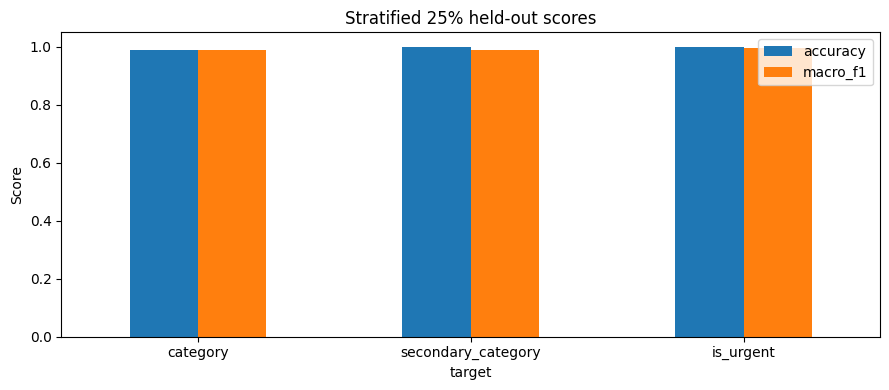

In [2]:
scores = pd.DataFrame(metrics['validation']).T
scores.index.name = 'target'
display((100 * scores).round(2).rename(columns={'accuracy':'accuracy (%)','macro_f1':'macro-F1 (%)'}))
scores.plot.bar(figsize=(9,4), ylim=(0,1.05), rot=0, title='Stratified 25% held-out scores')
plt.ylabel('Score')
plt.tight_layout()
plt.show()

## Model configurations and rationale
Word 1–2 grams represent issue phrases; character n-grams capture spelling variation, morphology, Unicode scripts, and transliteration. Ticket channel, optional language, subject, and text are inputs; ticket IDs are excluded. NFC normalization is applied. Linear TF-IDF models are sparse, fast to serve locally, and require no external inference API. Logistic regression provides probabilities for the primary/urgency tasks. A sigmoid-calibrated linear SVM provides probabilities for optional secondary routing.

In [3]:
rows=[]
for target, cfg in config['models'].items():
    rows.append({'target':target,'estimator':cfg['estimator'],'C':cfg['C'],'class_weight':cfg['class_weight'],'normalize':cfg['normalize'],'char_analyzer':cfg['char_analyzer'],'char_ngrams':cfg['char_ngram_range'],'threshold':cfg.get('threshold','argmax')})
display(pd.DataFrame(rows).set_index('target'))
print('Primary: balanced Logistic Regression C=100; word 1–2 + char_wb 2–6. Balanced weights address class imbalance.')
print('Secondary: sigmoid-calibrated Linear SVM C=1; threshold 0.20 for optional, distinct secondary labels.')
print('Urgency: balanced Logistic Regression C=40; threshold 0.30 for probability-based urgent routing.')

,estimator,C,class_weight,normalize,char_analyzer,char_ngrams,threshold
target,,,,,,,
category,logistic_regression,100.0,balanced,False,char_wb,"[2, 6]",argmax
secondary_category,calibrated_svm,1.0,None,True,char,"[2, 6]",0.2
is_urgent,logistic_regression,40.0,balanced,True,char,"[2, 5]",0.3


Primary: balanced Logistic Regression C=100; word 1–2 + char_wb 2–6. Balanced weights address class imbalance.
Secondary: sigmoid-calibrated Linear SVM C=1; threshold 0.20 for optional, distinct secondary labels.
Urgency: balanced Logistic Regression C=40; threshold 0.30 for probability-based urgent routing.


## Per-class metrics and confusion matrices
All class precision, recall, F1 and support values are shown. The final release notebook contains visual confusion matrices for all three outputs.


category


,precision,recall,f1-score,support
account_promo,0.9889,0.9889,0.9889,90.0
app_technical,0.9756,1.0000,0.9877,80.0
delivery_delay,0.9740,1.0000,0.9868,150.0
food_quality,1.0000,0.9857,0.9928,70.0
general_inquiry,0.9804,1.0000,0.9901,50.0
lost_item,0.9796,0.9600,0.9697,50.0
order_missing_wrong,1.0000,0.9833,0.9916,120.0
payment_refund,1.0000,0.9944,0.9972,180.0
ride_trip_issue,0.9928,0.9857,0.9892,140.0
safety_conduct,1.0000,0.9750,0.9873,40.0



secondary_category


,precision,recall,f1-score,support
__none__,1.0000,0.9989,0.9994,903.0
app_technical,1.0000,1.0000,1.0000,16.0
delivery_delay,1.0000,0.9286,0.9630,14.0
order_missing_wrong,1.0000,1.0000,1.0000,8.0
payment_refund,0.9375,1.0000,0.9677,30.0
ride_trip_issue,1.0000,1.0000,1.0000,29.0
macro avg,0.9896,0.9879,0.9884,1000.0
weighted avg,0.9981,0.9980,0.9980,1000.0



is_urgent


,precision,recall,f1-score,support
false,0.9989,1.0000,0.9994,905.0
true,1.0000,0.9895,0.9947,95.0
macro avg,0.9994,0.9947,0.9971,1000.0
weighted avg,0.9990,0.9990,0.9990,1000.0


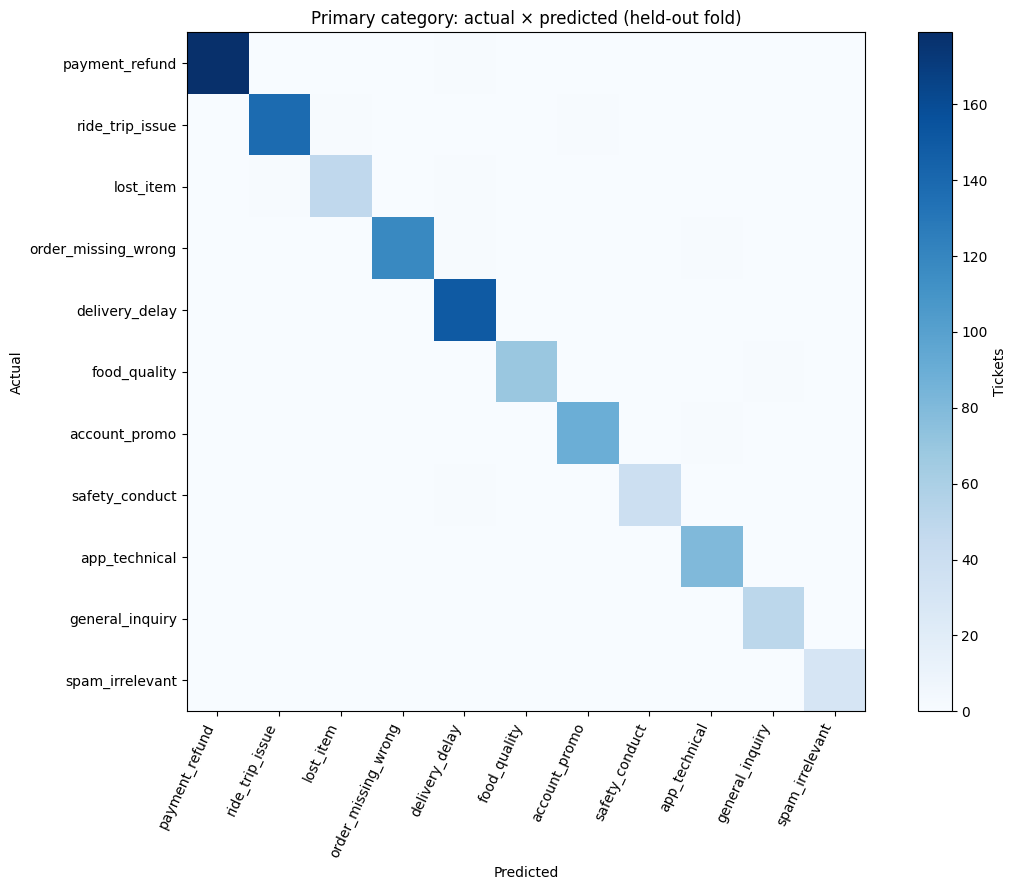

In [4]:
for target, report in metrics['classification_reports'].items():
    print('\n'+target)
    display(pd.DataFrame({label:value for label,value in report.items() if isinstance(value,dict)}).T[['precision','recall','f1-score','support']].round(4))
labels=metrics['category_confusion_matrix']['labels']
matrix=metrics['category_confusion_matrix']['rows_actual_columns_predicted']
fig,ax=plt.subplots(figsize=(12,9))
image=ax.imshow(matrix,cmap='Blues')
ax.set(title='Primary category: actual × predicted (held-out fold)',xlabel='Predicted',ylabel='Actual',xticks=range(len(labels)),yticks=range(len(labels)))
ax.set_xticklabels(labels,rotation=65,ha='right'); ax.set_yticklabels(labels)
fig.colorbar(image,ax=ax,label='Tickets'); fig.tight_layout(); plt.show()

## Language and the reported routing issue
Language subgroup sizes differ substantially; the small mixed and Tanglish groups should be interpreted cautiously. The delay/lost-property pair is isolated from the held-out confusion matrix below.

,count,accuracy,macro_f1
en,356.0,0.9831,0.9825
mixed,23.0,1.0000,1.0000
si,198.0,1.0000,1.0000
singlish,255.0,0.9961,0.9978
ta,146.0,1.0000,1.0000
tanglish,22.0,0.8636,0.7778


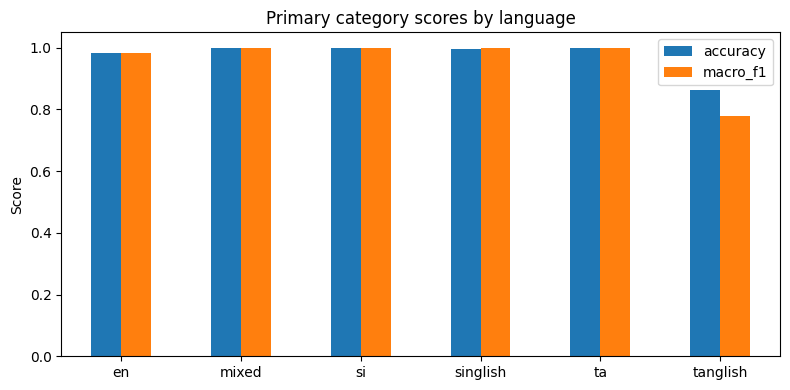

,predicted lost_item,predicted delivery_delay
actual lost_item,48,1
actual delivery_delay,0,150


In [5]:
language_scores=pd.DataFrame(metrics['category_by_language']).T.sort_index()
display(language_scores)
language_scores[['accuracy','macro_f1']].plot.bar(figsize=(8,4),ylim=(0,1.05),title='Primary category scores by language')
plt.ylabel('Score'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
labels=metrics['category_confusion_matrix']['labels']; matrix=metrics['category_confusion_matrix']['rows_actual_columns_predicted']
li=labels.index('lost_item'); di=labels.index('delivery_delay')
display(pd.DataFrame([[matrix[li][li],matrix[li][di]],[matrix[di][li],matrix[di][di]]],index=['actual lost_item','actual delivery_delay'],columns=['predicted lost_item','predicted delivery_delay']))

## Release
Version `v2.1.0`; model artifact version `tf-phase2-drive-2.1.0`. The final artifact was fitted on 4,800 labeled rows after the holdout evaluation. The current production deployment was verified to load this version and route a delayed order to Delivery Operations and a personal item left during a ride to Lost & Found. For reproducibility run `python scripts/train_model.py`; for the full report open [final_model_release.ipynb](final_model_release.ipynb). Synthetic data and possible repeated templates limit generalization; validate on new human-reviewed tickets before live operational use.